# 07 · Groei, voederopname en voederconversie onderzoeken

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

Op het proefbedrijf hebben twee aparte toestellen de gewichten en de voederopnames gemeten. Via MQTT en de API heb je beide bronnen verzameld in jouw analysedatabase op de kantoorcomputer. Nu leg je ze samen om per hok te zien hoe snel de biggen groeien en hoeveel voer daarvoor nodig is.

Je start met één enkel dier over één vaste periode. Daarna maak je voor alle hokken grafieken van het gewicht, de gemiddelde groei, de voederopname en de voederconversie, en let je op hoeveel dieren er telkens echt meedoen. Tot slot bewaar je deze beginsituatie, zodat je in notebook 08 kunt zien wat de extra meetdagen veranderen.

**Nodig:** je Codespace en eigen branch, een afgerond notebook 06 en `gegevens/werk/analyse_06.db`. Je gebruikt beide datasets, ongeacht je oorspronkelijke rol. De API hoeft niet actief te zijn, want alle nodige gegevens staan al lokaal in je analysedatabase.

Voer de cellen in volgorde uit. In twee vrijblijvende verkenningen kun je zelf nog een extra vergelijking proberen.

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Tip bij heruitvoeren.** Bestaat er bij jou nog een oudere map `gegevens/inlevering/beginsituatie_07` van een vorige ronde? Hernoem of verplaats die oude map en het oude controlebestand dan eerst (bijvoorbeeld naar `beginsituatie_07_oud`), want een bestaande beginsituatie wordt nooit automatisch overschreven. Als je `analyse_06.db` intussen al aangevuld hebt, voer dan eerst de controle in notebook 06 opnieuw uit.

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Vooruitblik op notebook 08.** Hier leg je de rekenmethode en de beginsituatie vast voor de eerste vier weken. In notebook 08 voeg je nieuwe metingen toe, vergelijk je de hokken rond de voerwissels op dag 10 en dag 18 en kies je een voederstrategie. De tabellen hier gebruiken nog gram per dier per dag, terwijl het eindoverzicht in notebook 08 met kilogram per dier per dag werkt (gedeeld door 1.000). De voederconversie zelf blijft daardoor gelijk.

</div>

## 1. De analysedatabase en de vorige controle ophalen

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Uitvoeren:** in Codespaces (Notebook 07)

De gegevens staan lokaal op je analysecomputer in Codespaces. De code opent `analyse_06.db` alleen om te lezen, zodat je oorspronkelijke meetgegevens veilig blijven terwijl je rekent en grafieken maakt.

De eerste cel controleert of de database overeenkomt met je controlebestand uit notebook 06 en laadt meteen alle kolommen en hoknummers die nodig zijn voor de analyse.

</div>

In [1]:
_DOCENT_BRANCH_OVERRIDE = "student/proefdocent"

In [2]:
from pathlib import Path
from datetime import datetime, timezone
import json
import re
import subprocess
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

r = subprocess.run(["git", "rev-parse", "--show-toplevel"], capture_output=True, text=True)
if r.returncode:
    raise RuntimeError("Open notebook 07 vanuit de practicumrepository.")
hoofdmap = Path(r.stdout.strip())
branch = subprocess.check_output(["git", "branch", "--show-current"], cwd=hoofdmap, text=True).strip()
if not re.fullmatch(r"student/[a-z0-9][a-z0-9_-]*", branch) and "_DOCENT_BRANCH_OVERRIDE" in globals():
    branch = _DOCENT_BRANCH_OVERRIDE
instellingen = json.loads((hoofdmap / "gegevens/inlevering/01_werkplekcontrole.json").read_text(encoding="utf-8"))
deelnemer, rol = instellingen["deelnemerscode"], instellingen["rol"]
if branch != "student/" + deelnemer or instellingen.get("branch") != branch or rol not in ("gewichten", "voederopname"):
    raise ValueError("Controleer je eigen branch en instellingen uit notebook 01.")
controle06 = json.loads((hoofdmap / "gegevens/inlevering/06_apicontrole.json").read_text(encoding="utf-8"))
if controle06.get("deelnemerscode") != deelnemer or controle06.get("branch") != branch or not controle06.get("inhoud_gelijk_aan_05"):
    raise ValueError("Rond notebook 06 en de automatische inlevering af.")
sys.path.insert(0, str(hoofdmap / "programmatuur"))
from analyse_07 import (lees_analyse, selecteer, daggewichten, schat_gewicht,
                       bereken_intervallen, vat_hokken_samen, bewaar_basis, METHODE, STANDAARD_GRENZEN)
from figuren_07 import gewichtsfiguur, intervalfiguur, hokvolgorde, procestijd, procesas
analysepad = hoofdmap / "gegevens/werk/analyse_06.db"
data, bronmanifest = lees_analyse(analysepad)
assert bronmanifest == controle06["herhaalde_import"]["bronnen"], "De database is veranderd sinds je controle uit 06."
print("Deelnemer:", deelnemer, "| Rol:", rol)
print("Gecontroleerde bronrecords:", len(data))
display(data.groupby(["bron", "meettype", "eenheid"]).size().rename("records").reset_index())

Deelnemer: proefdocent | Rol: gewichten
Gecontroleerde bronrecords: 226677


,bron,meettype,eenheid,records
0,asserva,gewichten,kg,80028
1,schauer,voederopname,g,146649


<div style="background-color:#e8f5e9;color:#1b5e20;border-left:5px solid #2e7d32;padding:14px;margin:12px 0;border-radius:4px;text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;white-space:normal;"><strong>Controle</strong><br>Je verwacht 80.028 gewichtsrecords in kg en 146.649 voederopnamerecords in g. Dat zijn de ruwe bronrijen: ze vertellen nog niet hoeveel dieren en periodes straks echt bruikbaar zijn in de berekening.</div>

## 2. Van bezoekregistratie naar een vergelijking tussen dieren

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

Een voederrecord geeft de voederopname tijdens één bezoek aan de trog. Om de totale opname in een periode te berekenen, tel je alle bezoeken in die periode bij elkaar op. Een gewichtsrecord toont daarentegen het lichaamsgewicht op één bepaald moment. Gewichten tel je dus niet op, maar vergelijk je tussen een begin- en eindpunt om groei te bepalen.

Je koppelt beide bronnen via het diernummer (`dier_id`), terwijl het hoknummer aangeeft bij welke groep het dier hoort. Een dier telt alleen mee als het in beide bronnen consequent aan hetzelfde hok gekoppeld is, zodat onbekende of foutieve registraties geen groep vertekenen.

Bekijk eerst de kwaliteitscodes en herkomst van de metingen, want die zijn tijdens de hele overdracht bewaard gebleven. Een geïmputeerd gewicht is een waarde die eerder geschat werd, en een voederbezoek met waarde nul is een geregistreerd bezoek zonder opname.

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Procestijd: tijd sinds de start van de proef.** Een kalenderdatum zegt wanneer iets gebeurde, terwijl procestijd aangeeft hoeveel dagen er sinds het begin verstreken zijn. We kiezen één gezamenlijk nulpunt: het allereerste meetmoment in beide bronnen samen, nog voordat we records wegfilteren. Zo gebruiken gewichten en voederopnames precies dezelfde klok en verschuift de tijdas niet bij het selecteren.

Voor elke meting trekken we dat starttijdstip af en delen we het verschil in seconden door 86.400. Een meting 1 dag en 12 uur na de start krijgt zo procestijd 1,5. We groeperen gegevens dus niet grofweg per hele dag voordat we rekenen: de asstreepjes op hele dagen dienen alleen voor de leesbaarheid.

De stippellijnen op dag 10 en dag 18 geven de momenten aan waarop het voer mogelijk gewisseld werd. Bij intervalgrafieken staat elk punt in het midden van zijn meetperiode en toont het horizontale lijntje hoe lang die periode duurde. Een interval dat zo'n voerwissel overlapt, zegt daardoor nog niets aparts over vóór of na die wissel.

</div>

In [3]:
from figuren_07 import procestijd, procesas
processtart = pd.to_datetime(data["tijd"]).min()
print("Procestijd 0:", processtart)
voorbeeld_tijd = pd.to_datetime(data["tijd"]).head(5)
display(pd.DataFrame({"tijdstip": voorbeeld_tijd,
                      "procestijd_dagen": procestijd(voorbeeld_tijd, processtart)}))
for dagnummer in (10, 18):
    print(f"Dag {dagnummer}:", processtart + pd.Timedelta(days=dagnummer))

Procestijd 0:

 2023-08-24 12:00:00


,tijdstip,procestijd_dagen
0,2023-08-24 12:00:00,0.000000
1,2023-08-24 13:35:13,0.066123
2,2023-08-24 13:45:45,0.073438
3,2023-08-24 13:48:52,0.075602
4,2023-08-24 13:51:32,0.077454


Dag 10: 2023-09-03 12:00:00
Dag 18: 2023-09-11 12:00:00


In [4]:
filteraantallen = data.groupby(["bron", "vlag"], dropna=False).size().rename("rijen").reset_index()
display(filteraantallen)
filteroverzicht = data.assign(behouden=data.vlag.eq("0")).groupby("bron").agg(
    totaal=("vlag", "size"), behouden_filter_0=("behouden", "sum"))
filteroverzicht["uitgesloten"] = filteroverzicht.totaal - filteroverzicht.behouden_filter_0
display(filteroverzicht)
display(data.groupby(["bron", "foutcode", "vlag"], dropna=False).size().rename("records").reset_index())
display(data[data["bron"] == "asserva"].groupby("herkomst", dropna=False).size().rename("gewichtsrecords").reset_index())
print("Geregistreerde nulbezoeken in de voederbron:", int(((data["bron"] == "schauer") & (data["waarde"] == 0)).sum()))

,bron,vlag,rijen
0,asserva,0,71115
1,asserva,errored,7
2,asserva,flagged,8906
3,schauer,0,74690
4,schauer,errored,80
5,schauer,flagged,71879


,totaal,behouden_filter_0,uitgesloten
bron,,,
asserva,80028,71115,8913
schauer,146649,74690,71959


,bron,foutcode,vlag,records
0,asserva,invalid PEN,errored,7
1,asserva,no error,0,71115
2,asserva,no error,flagged,8906
3,schauer,no error,0,74690
4,schauer,no error,flagged,71879
5,schauer,non-pig EID,errored,80


,herkomst,gewichtsrecords
0,0,78614
1,allocation,101
2,exit,2
3,imputed,1112
4,manualweighing,199


Geregistreerde nulbezoeken in de voederbron: 58924


<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Vraag 1.** Waarom is een voederrecord met waarde nul niet hetzelfde als een ontbrekende voederdag?

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Jouw antwoord (Vraag 1):**

*Voeg hier je antwoord in. Tip: vergelijk een waargenomen bezoek met een periode zonder registratie.*

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Antwoord 1**

Een voederrecord met waarde nul betekent dat het dier wel degelijk in de trog herkend is, maar toen niets heeft gegeten. Op een dag zonder records weten we niet of het dier niet is gaan eten, de oorbelherkenning haperde of de registratie uitviel. In deze analyse tellen we alle aanwezige bezoeken op. Een ontbrekende dag sluit het dier niet uit, al kan de totale opname dan wel onderschat zijn. Heeft een dier in een hele periode geen enkel geregistreerd bezoek, dan blijft de opname onbekend en vullen we geen nul in.

</div>

## 3. De populatie, periode en kwaliteitsregels vastleggen

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Uitvoeren:** in Codespaces (Notebook 07)

Elke uitkomst hangt af van welke dieren, welke periode en welke kwaliteitsregels je kiest. Daarom leggen we die keuzes helder vast voordat we gaan rekenen. Dit is een eenvoudige, overzichtelijke lesmethode en dus geen exacte kopie van alle stappen uit de oorspronkelijke onderzoekspijplijn.

Je sluit in de analyse alleen records uit die als fout zijn gemarkeerd, en je gebruikt alleen dieren die in beide bronnen aan hetzelfde hok hangen. Voor gewichten neem je echte wegingen mee (toestelmetingen, handmatige wegingen en startweging). Eerder geschatte (*geïmputeerde*) gewichten en uitstroomregistraties houden we apart. In de database zelf blijft natuurlijk alles gewoon staan.

**Verplichte filter: `FILTER = '0'`.** De kolom `FILTER` heet in de Python-tabel `vlag` en bevat tekst, dus je vergelijkt met `'0'` en niet met het getal `0`. Alleen rijen met `'0'` tellen mee voor groei, opname, conversie en grafieken. Rijen met `flagged` of `errored` zijn bij een eerdere verwerking gemarkeerd als uitschieters of fouten en blijven buiten de analyse. Bij voederopname zijn dat vaak bezoeken met heel weinig of geen opname. We gooien dus niet zelf willekeurig kleine waarden weg, maar volgen de bestaande kwaliteitsvlag.

De tabel hieronder toont per kwaliteitscode hoeveel rijen overblijven en hoeveel er afvallen. Voor de eerste vier weken blijven op basis van `FILTER` 71.115 van de 80.028 gewichtsrijen en 74.690 van de 146.649 voederrijen over. Daarna vallen er via de overige controles nog enkele rijen af.

</div>

In [5]:
basis_vanaf = "2023-08-24"
basis_tot = "2023-09-21"  # Exclusieve bovengrens van de aangeleverde basisdata.
gewichten, voeder, populatie, selectiecontrole, koppeling_uitgesloten = selecteer(
    data, vanaf=basis_vanaf, tot=basis_tot
)
display(selectiecontrole)
display(populatie.groupby("hok").size().rename("dieren").reindex(hokvolgorde(populatie["hok"])).reset_index())
print("Gekoppelde dieren:", len(populatie))
print("Dieren met onzekere koppeling:", len(koppeling_uitgesloten))
assert set(populatie["hok"]) == {str(i) for i in range(1, 11)}
assert gewichten.vlag.eq("0").all() and voeder.vlag.eq("0").all()

,stap,bron,over,uitgesloten
0,Gekozen bronperiode,asserva,80028,0
1,Gekozen bronperiode,schauer,146649,0
2,Geldige herkenning,asserva,80021,7
3,Geldige herkenning,schauer,146569,80
4,Stabiel gekoppelde dieren,asserva,80021,0
5,Stabiel gekoppelde dieren,schauer,146569,0
6,Geldige tijd en waarde,asserva,80021,0
7,Geldige tijd en waarde,schauer,146569,0
8,Oorspronkelijke gewichten,asserva,78907,1114
9,Oorspronkelijke gewichten,schauer,146569,0


,hok,dieren
0,1,11
1,2,10
2,3,10
3,4,10
4,5,10
5,6,10
6,7,10
7,8,10
8,9,10
9,10,10


Gekoppelde dieren: 101
Dieren met onzekere koppeling: 0


<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

De eerste dag in de bestanden begint pas rond de middag, terwijl je voor een begin- en eindgewicht ook metingen rond die tijdstippen nodig hebt. Daarom berekenen we de vaste periode van **25 augustus om 00:00 tot 20 september om 00:00**. De resterende wegingen op 20 september helpen nog om het eindgewicht zo goed mogelijk te schatten, zonder al latere meetdagen te gebruiken.

Die periode splitsen we op in drie intervallen van zeven dagen en een laatste interval van vijf dagen. Groei en voederopname rekenen we om naar gram per dier per dag, zodat intervallen van vijf en zeven dagen toch eerlijk te vergelijken zijn.

</div>

In [6]:
grenzen = STANDAARD_GRENZEN.copy()
regels = {
    "basis_vanaf": basis_vanaf, "basis_tot_exclusief": basis_tot,
    "grenzen": grenzen, "grensgewicht": "gemiddelde vijf dichtste individuele metingen", "aantal_gewichten": 5,
    "filter": "uitsluitend tekst 0", "flagged": "uitgesloten", "imputed_en_exit": "uitgesloten",
    "voedertoewijzing": "bezoekstart, begin inclusief, einde exclusief",
    "dekking": "som van alle behouden bezoeken per interval, minstens één record per interval",
    "groei": "uitsluitend positieve groei voor voederconversie",
}
display(pd.DataFrame({"vanaf": grenzen[:-1], "tot_exclusief": grenzen[1:],
                      "dagen": np.diff(pd.to_datetime(grenzen)).astype("timedelta64[D]").astype(int)}))

,vanaf,tot_exclusief,dagen
0,2023-08-25,2023-09-01,7
1,2023-09-01,2023-09-08,7
2,2023-09-08,2023-09-15,7
3,2023-09-15,2023-09-20,5


<div style="background-color:#e8f5e9;color:#1b5e20;border-left:5px solid #2e7d32;padding:14px;margin:12px 0;border-radius:4px;text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;white-space:normal;"><strong>Interpretatie</strong><br>Als een dier in een interval niet groeit (groei kleiner dan of gelijk aan nul), berekenen we geen voederconversie. Zulke dieren verdwijnen niet spoorloos: de reden blijft zichtbaar in het overzicht. Omdat alleen dieren met positieve groei meetellen, kan een hokgemiddelde soms gunstiger lijken dan het beeld van alle dieren samen. Bekijk daarom altijd zowel de waarde als het aantal meegenomen dieren.</div>

## 4. Een gewichtsverloop opbouwen

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Uitvoeren:** in Codespaces (Notebook 07)

Voor de gewichtsgrafiek per dag berekenen we eerst één mediaan per dier en per dag, zodat een dier dat tien keer op een dag op de weegschaal staat niet tien keer zo zwaar doorweegt in het hokgemiddelde. Die dagmedianen gebruiken we alleen om de groeilijn in de tijd te tekenen.

**Het gewicht op een periodegrens berekenen we op een andere manier.** We leggen eerst de exacte begintijd en eindtijd vast. Daarna zoeken we per dier de vijf individuele gewichtsmetingen (met `FILTER = '0'`) die in tijd het dichtst bij die grens liggen, zowel net ervoor als net erna. Het gewone gemiddelde van die vijf metingen wordt het geschatte grensgewicht. We gebruiken hier dus vijf losse metingen, geen vijf dagmedianen.

Er zit geen vaste bovengrens op hoe ver die vijf metingen van de grens mogen liggen, maar `afstand_begin_uren` en `afstand_eind_uren` tonen wel hoe ver de verst gelegen meting afweek. Ook als alle vijf metingen aan dezelfde kant van de grens vallen, berekenen we het gemiddelde. Alleen bij minder dan vijf wegingen voor een dier blijft het grensgewicht onbekend. Liggen twee metingen precies even ver weg, dan krijgt de vroegste voorrang.

Dat bijna alle dieren zo een waarde krijgen, betekent niet automatisch dat elk grensgewicht even betrouwbaar is. Let daarom op de tijdafstand, vooral bij een dier dat later niet meer gewogen is: een gemiddelde van oude wegingen zegt immers niets over zijn gewicht weken later.

</div>

,dier_id,hok,dag,tijd,gewicht_kg,metingen
0,89728010,3,2023-08-24,2023-08-24 13:55:46.000,7.010,7
1,89728010,3,2023-08-25,2023-08-25 14:41:01.000,6.730,3
2,89728010,3,2023-08-27,2023-08-27 20:50:00.000,7.610,3
3,89728010,3,2023-08-28,2023-08-28 14:52:13.500,7.655,18
4,89728010,3,2023-08-29,2023-08-29 12:24:27.000,7.815,22
5,89728010,3,2023-08-30,2023-08-30 15:16:48.000,8.000,21
6,89728010,3,2023-08-31,2023-08-31 13:43:40.000,8.055,20


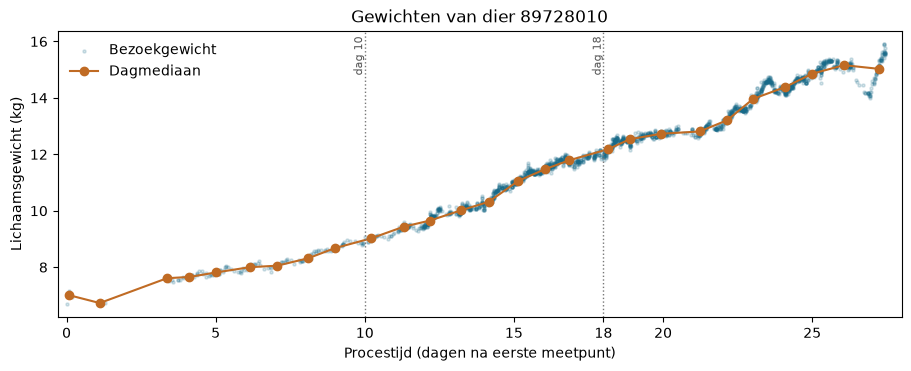

In [7]:
dag = daggewichten(gewichten)
voorbeeld_dier = populatie.iloc[0]["dier_id"]
voorbeeld_dagen = dag[dag["dier_id"] == voorbeeld_dier]
display(voorbeeld_dagen.head(7))
fig, ax = plt.subplots(figsize=(9, 3.6), layout="constrained")
ruw = gewichten[gewichten["dier_id"] == voorbeeld_dier]
ax.scatter(procestijd(ruw["tijd"], processtart), ruw["waarde"], s=5, alpha=.18, color="#176a89", label="Bezoekgewicht")
ax.plot(procestijd(voorbeeld_dagen["tijd"], processtart), voorbeeld_dagen["gewicht_kg"], "o-", color="#c06b24", label="Dagmediaan")
ax.set(title=f"Gewichten van dier {voorbeeld_dier}", xlabel="Procestijd (dagen)", ylabel="Lichaamsgewicht (kg)")
procesas(ax, 0, procestijd(gewichten.tijd.max(), processtart))
ax.legend(frameon=False)
plt.show()

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

*Figuur 1. Bezoekgewichten en dagmedianen van één dier. De verbindingslijn maakt het verloop zichtbaar, maar stelt geen voortdurend gemeten gewicht voor.*

</div>

<div style="background-color:#e3f2fd;color:#0d47a1;border-left:5px solid #1976d2;padding:14px;margin:12px 0;border-radius:4px;text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;white-space:normal;"><strong>Facultatieve verkenning 1</strong><br>Hoeveel verschillen de dieren binnen één hok op dezelfde dag? Bereken voor een gekozen hok en dag de mediaan en het eerste en derde kwartiel van de dagmedianen per dier, en vergelijk dat eens met een ander hok. Geef je variabelen een naam als <code>verkenning_...</code>, zodat de basisvariabelen intact blijven.</div>

In [8]:
# FACULTATIEF: kies een hok en dag.
# Selecteer rijen uit dag en gebruik .quantile([0.25, 0.5, 0.75]) op gewicht_kg.
# Verklaar of je spreiding tussen dieren of tussen bezoeken van hetzelfde dier onderzoekt.

In [9]:
verkenning_hok = "1"
verkenning_dag = pd.Timestamp("2023-09-10")
verkenning_selectie = dag[(dag["hok"] == verkenning_hok) & (dag["dag"] == verkenning_dag)]
display(verkenning_selectie["gewicht_kg"].quantile([0.25, 0.5, 0.75]).rename("gewicht_kg"))
print("Deze spreiding betreft verschillen tussen dieren, elk vertegenwoordigd door één dagmediaan.")

0.25    11.8125
0.50    13.1900
0.75    14.2550
Name: gewicht_kg, dtype: float64

Deze spreiding betreft verschillen tussen dieren, elk vertegenwoordigd door één dagmediaan.


## 5. Eén geïntegreerde berekening volgen

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Uitvoeren:** in Codespaces (Notebook 07)

Voor elk dier is de groei in een interval het eindgewicht min het begingewicht (beide telkens het gemiddelde van vijf wegingen). De voederopname is de som van alle geldige voederbezoeken (`FILTER = '0'`) in dat interval, gedeeld door 1.000 om gram om te zetten naar kilogram.

Een bezoek hoort bij een interval als de starttijd op of na de begingrens en vóór de eindgrens valt (de eindgrens zelf telt dus al bij het volgende interval). Valt een bezoek net over een grens heen, dan tellen we het volledig mee in het interval waarin het begon.

Een dier hoeft niet op elke dag van het interval een bezoek te hebben. We tonen het aantal dagen met registraties wel als extra controle, maar sluiten een dier daarop niet uit. Alleen als er in een heel interval geen enkel geldig voederbezoek is, blijft de opname onbekend, en bij groei kleiner dan of gelijk aan nul berekenen we geen voederconversie.

</div>

| Berekening | Formule | Eenheid |
|---|---|---|
| Gewichtstoename | Eindgewicht − begingewicht | kg |
| Gemiddelde dagelijkse groei | Gewichtstoename × 1000 / dagen | g per dier per dag |
| Gemiddelde dagelijkse voederopname | Voederopname in kg × 1000 / dagen | g per dier per dag |
| Voederconversie | Voederopname in kg / gewichtstoename in kg | kg voeder per kg groei |

In [10]:
dierintervallen = bereken_intervallen(gewichten, voeder, populatie, grenzen)
voorbeeld = dierintervallen[dierintervallen["bruikbaar"]].iloc[0]
toename = voorbeeld["eind_kg"] - voorbeeld["begin_kg"]
opname = voorbeeld["voeder_kg"]
print("Dier:", voorbeeld["dier_id"], "| Hok:", voorbeeld["hok"])
print("Periode:", voorbeeld["vanaf"], "tot", voorbeeld["tot"], "(exclusief)")
print(f"Gewicht: {voorbeeld['begin_kg']:.3f} naar {voorbeeld['eind_kg']:.3f} kg")
print(f"Groei: {toename:.3f} kg / {voorbeeld['dagen']} dagen = {1000 * toename / voorbeeld['dagen']:.1f} g/dag")
print(f"Voeder: {opname:.3f} kg / {voorbeeld['dagen']} dagen = {1000 * opname / voorbeeld['dagen']:.1f} g/dag")
print(f"Voederconversie: {opname:.3f} / {toename:.3f} = {opname / toename:.3f} kg/kg")
assert np.isclose(opname / toename, voorbeeld["voederconversie"])
# Bekijk de vijf waarnemingen die het begingewicht bepalen.
metingen_voorbeeld = gewichten[gewichten.dier_id.eq(voorbeeld.dier_id)].sort_values("tijd").copy()
metingen_voorbeeld["afstand_uren"] = (metingen_voorbeeld.tijd - voorbeeld.vanaf).abs().dt.total_seconds() / 3600
display(metingen_voorbeeld.nsmallest(5, "afstand_uren")[["tijd", "waarde", "afstand_uren"]])
print("Maximale afstand tot begin- en eindpunt (uren):",
      round(voorbeeld.afstand_begin_uren, 1), round(voorbeeld.afstand_eind_uren, 1))

Dier: 89728010 | Hok: 3
Periode: 2023-08-25 00:00:00 tot 2023-09-01 00:00:00 (exclusief)
Gewicht: 7.044 naar 8.230 kg
Groei: 1.186 kg / 7 dagen = 169.4 g/dag
Voeder: 1.459 kg / 7 dagen = 208.4 g/dag
Voederconversie: 1.459 / 1.186 = 1.230 kg/kg


,tijd,waarde,afstand_uren
9,2023-08-24 16:02:20,6.93,7.961111
8,2023-08-24 15:41:34,7.02,8.307222
7,2023-08-24 14:11:45,6.99,9.804167
5,2023-08-24 13:55:46,7.11,10.070556
3,2023-08-24 13:48:52,7.17,10.185556


Maximale afstand tot begin- en eindpunt (uren): 10.2 3.8


<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Vraag 2.** Wat betekent de berekende voederconversie van dit dier in gewone woorden?

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Jouw antwoord (Vraag 2):**

*Voeg hier je antwoord in. Tip: gebruik de getallen uit jouw uitvoer en benoem zowel het voeder als de groei.*

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Antwoord 2**

Dier `89728010` in hok 3 at in dit interval 1.459 kg voer en groeide naar schatting 1.186 kg, wat een voederconversie van 1.230 kg voer per kg groei oplevert. De gebruikte begin- en eindgewichten zijn gemiddelden van vijf individuele metingen (waarvan de code ook de tijdafstand toont). Die verhouding beschrijft dus het rendement in dat specifieke interval en niet een dagelijkse hoeveelheid voer.

</div>

## 6. Controleren welke dierintervallen bruikbaar zijn

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Uitvoeren:** in Codespaces (Notebook 07)

Voordat je hokken onderling vergelijkt, kijk je eerst hoeveel dieren er per interval afvallen. Een dier kan namelijk in het ene interval wel bruikbaar zijn en in het andere niet. In het overzicht blijft het totale aantal dieren zichtbaar onder `populatie`, terwijl `bruikbaar` laat zien hoeveel dieren in dat interval aan alle voorwaarden voldeden.

</div>

In [11]:
display(dierintervallen.groupby(["interval", "reden"]).size().rename("dierintervallen").reset_index())
dekking = dierintervallen.groupby("interval")["bruikbaar"].agg(["sum", "count"])
dekking.columns = ["bruikbaar", "populatie"]
display(dekking)
print("Bezoeken over de gekozen eindgrenzen:", int(dierintervallen["grensbezoeken"].sum()))

,interval,reden,dierintervallen
0,1,bruikbaar,98
1,1,geen_positieve_groei,3
2,2,bruikbaar,99
3,2,geen_voederrecords;geen_positieve_groei,2
4,3,bruikbaar,99
5,3,geen_voederrecords;geen_positieve_groei,2
6,4,bruikbaar,99
7,4,geen_voederrecords;geen_positieve_groei,2


,bruikbaar,populatie
interval,,
1,98,101
2,99,101
3,99,101
4,99,101


Bezoeken over de gekozen eindgrenzen: 0


<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Vraag 3.** Welk interval heeft de laagste dekking, en waarom vraagt dat extra voorzichtigheid bij een vergelijking?

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Jouw antwoord (Vraag 3):**

*Voeg hier je antwoord in. Tip: gebruik het aantal bruikbare dieren en minstens één uitsluitingsreden uit de tabel.*

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Antwoord 3**

In het eerste interval zijn 98 van de 101 dieren bruikbaar, in de drie latere intervallen telkens 99. Ontbrekende voederdagen sluiten een dier hier niet uit, maar een volledig lege voederperiode of een niet-positieve groei verhindert nog steeds het berekenen van de voederconversie. Ook als een dier wel meetelt, blijft het belangrijk om de tijdafstand van de vijf gebruikte gewichten te controleren.

</div>

## 7. Van dieren naar hokken rekenen

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Uitvoeren:** in Codespaces (Notebook 07)

Voor een hok neem je alleen de dieren die zowel voor voederopname als voor gewichtstoename bruikbaar zijn, en tel je eerst al hun voeder en groei apart bij elkaar op. De voederconversie van het hok is daarna het totale voer gedeeld door de totale groei. Je neemt dus niet het simpele gemiddelde van de losse conversies per dier, want dan zou een dier met heel weinig groei net zo zwaar wegen als een dier dat veel groeide.

De gemiddelde groei en opname per dier per dag bereken je door diezelfde totalen te delen door het aantal meegenomen dieren en het aantal dagen in het interval. Bij een hok met onvolledige dekking geldt dat resultaat dus alleen voor de dieren die meededen.

</div>

In [12]:
hokresultaten = vat_hokken_samen(dierintervallen)
kolommen = ["hok", "interval", "dagen", "dieren_bruikbaar", "dieren_populatie",
            "groei_g_dier_dag", "voeder_g_dier_dag", "voederconversie"]
display(hokresultaten[kolommen].round(3))
hokvoorbeeld = hokresultaten[(hokresultaten["hok"] == "1") & (hokresultaten["interval"] == 1)].iloc[0]
print(f"Hok 1, interval 1: {hokvoorbeeld['voeder_kg']:.3f} kg voer / {hokvoorbeeld['groei_kg']:.3f} kg groei")
print(f"Voederconversie: {hokvoorbeeld['voederconversie']:.3f} kg/kg")

,hok,interval,dagen,dieren_bruikbaar,dieren_populatie,groei_g_dier_dag,voeder_g_dier_dag,voederconversie
0,1,1,7,10,11,232.171,210.171,0.905
1,1,2,7,11,11,438.753,448.494,1.022
2,1,3,7,11,11,496.078,646.987,1.304
3,1,4,5,11,11,565.527,718.582,1.271
4,10,1,7,10,10,184.200,209.314,1.136
5,10,2,7,10,10,404.429,417.086,1.031
6,10,3,7,10,10,443.143,591.400,1.335
7,10,4,5,10,10,340.040,611.740,1.799
8,2,1,7,10,10,152.200,161.243,1.059
9,2,2,7,10,10,374.914,394.314,1.052


Hok 1, interval 1: 14.712 kg voer / 16.252 kg groei
Voederconversie: 0.905 kg/kg


<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Doe-opdracht.** Kies in `hokresultaten` een ander hok dan hok 1 en een interval naar keuze, en reken zelf na of `voeder_kg / groei_kg` precies dezelfde voederconversie geeft. Sla je keuzes op in `gekozen_hok` en `gekozen_interval`, en de gekozen rij in `eigen_resultaat`.

</div>

In [13]:
# SCHRIJF HIER JE CODE:
# 1. Kies gekozen_hok als tekst, bijvoorbeeld "9".
# 2. Kies gekozen_interval als geheel getal van 1 tot 4.
# 3. Selecteer de rij met beide voorwaarden en .iloc[0].
# 4. Bereken eigen_conversie = voeder_kg / groei_kg voor deze rij.

In [14]:
gekozen_hok = "9"
gekozen_interval = 4
eigen_resultaat = hokresultaten[(hokresultaten["hok"] == gekozen_hok) &
                              (hokresultaten["interval"] == gekozen_interval)].iloc[0]
eigen_conversie = eigen_resultaat["voeder_kg"] / eigen_resultaat["groei_kg"]

In [15]:
assert gekozen_hok in set(populatie["hok"]) and gekozen_hok != "1"
assert gekozen_interval in range(1, len(grenzen))
assert eigen_resultaat["hok"] == gekozen_hok and eigen_resultaat["interval"] == gekozen_interval
assert np.isclose(eigen_conversie, eigen_resultaat["voederconversie"])
print(f"Hok {gekozen_hok}, interval {gekozen_interval}: {eigen_conversie:.3f} kg voeder per kg groei")
print("Dieren meegenomen:", int(eigen_resultaat["dieren_bruikbaar"]), "van", int(eigen_resultaat["dieren_populatie"]))

Hok 9, interval 4: 1.236 kg voeder per kg groei
Dieren meegenomen: 10 van 10


## 8. De ontwikkeling per hok visualiseren

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Uitvoeren:** in Codespaces (Notebook 07)

Met grafieken zie je in één oogopslag of verschillen al vroeg ontstaan en of de volgorde tussen hokken door de tijd heen verschuift. Alle deelfiguren gebruiken dezelfde assen, zodat een andere schaal je niet op het verkeerde been zet.

Je begint met het gemiddelde lichaamsgewicht per hok, berekend als het gemiddelde van de beschikbare dagmedianen per dier. Omdat het aantal gewogen dieren per dag kan wisselen, kan een sprongetje in de lijn zowel door echte groei als door een licht gewijzigde samenstelling van de groep komen.

</div>

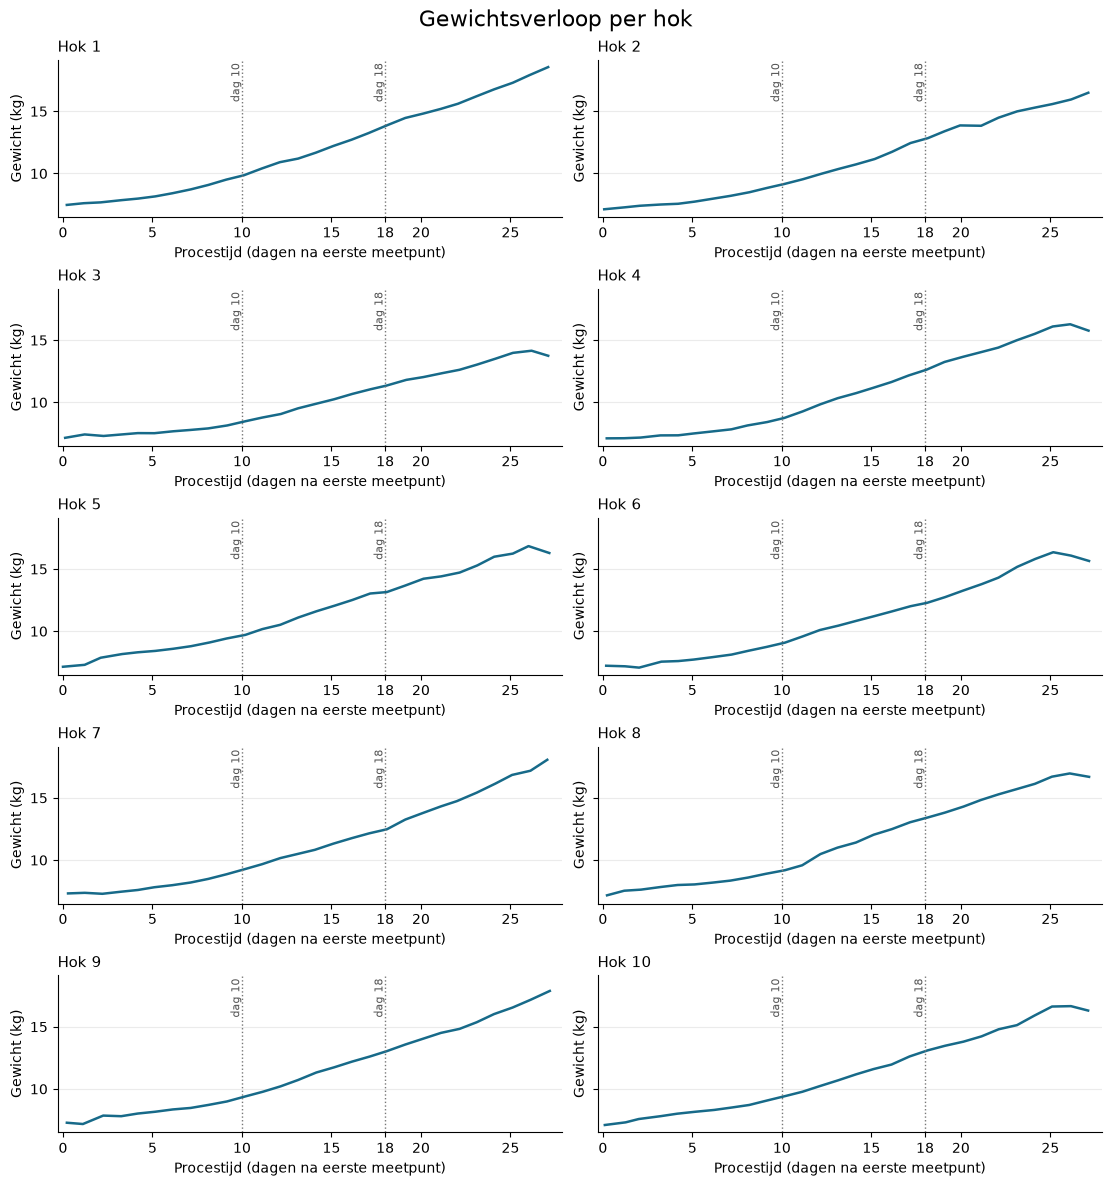

In [16]:
fig_gewicht = gewichtsfiguur(dag, start=processtart)
plt.show()

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

*Figuur 2. Gemiddelde van de beschikbare dagmedianen per dier per hok en kalenderdag. De lijn toont de gemiddelde waargenomen groep van die dag en is dus geen groeicurve van vaste dieren.*

Vergelijk daarna de gemiddelde groei en voederopname per interval. Beide staan in gram per dier per dag en gebruiken precies dezelfde bruikbare dieren. Elk punt vat het volledige interval samen en is geen losse dagmeting.

</div>

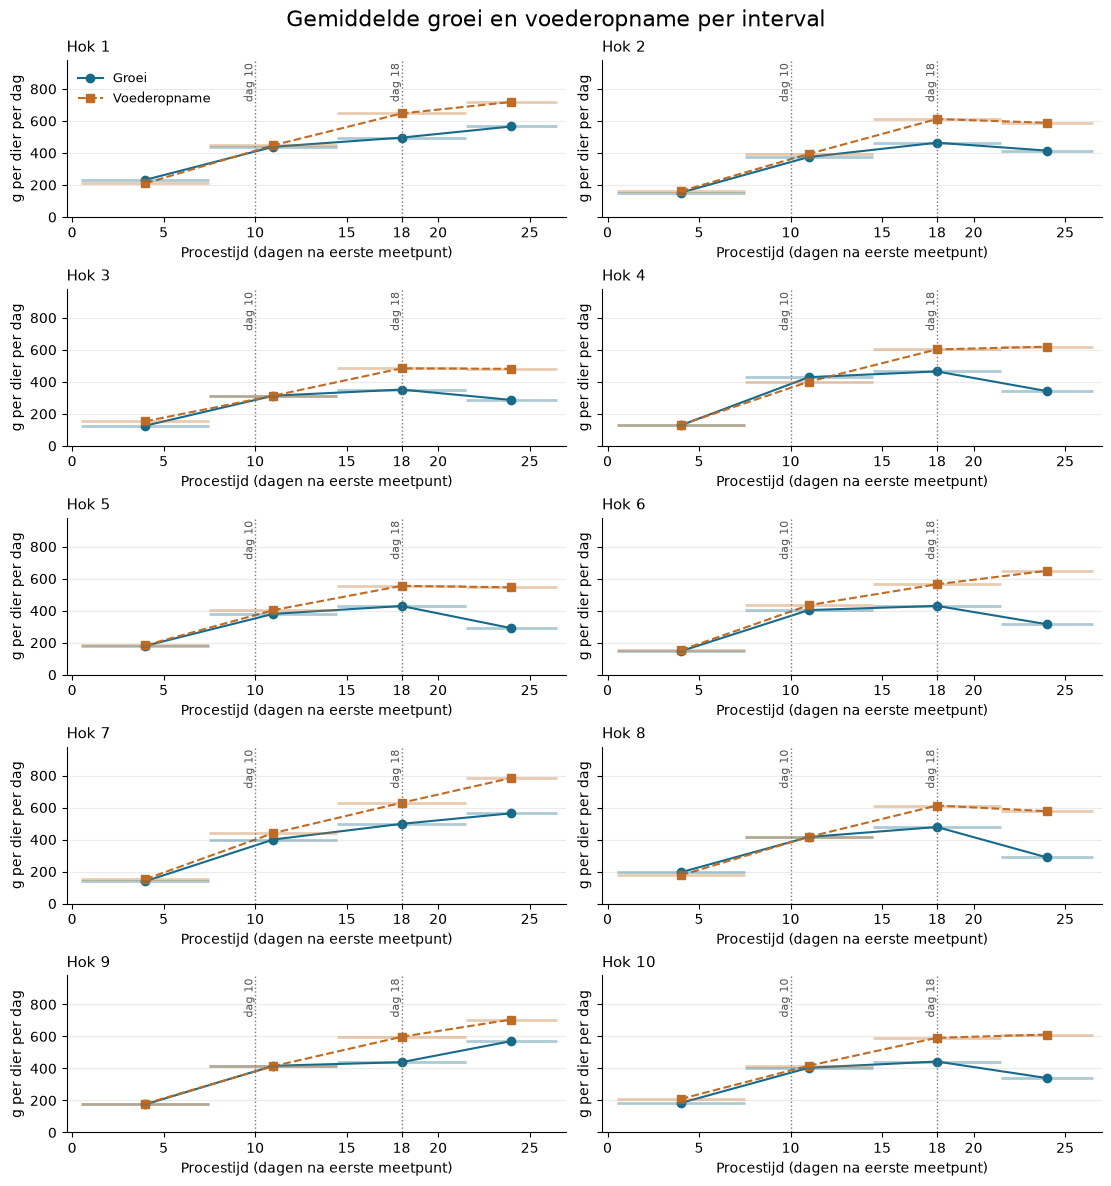

In [17]:
fig_groei_voeder = intervalfiguur(hokresultaten, "groei_voeder", start=processtart)
plt.show()

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

*Figuur 3. Gemiddelde groei en voederopname voor dezelfde bruikbare dieren per hokinterval. De laatste periode duurt vijf dagen, de eerste drie telkens zeven dagen.*

De volgende grafiek toont de voederconversie per hok en vermeldt bij elk punt hoeveel dieren meededen. Een lagere waarde betekent dat er minder voer geregistreerd werd per kilogram geschatte groei, al moet je dat altijd samen met de groeisnelheid en de dekking bekijken.

</div>

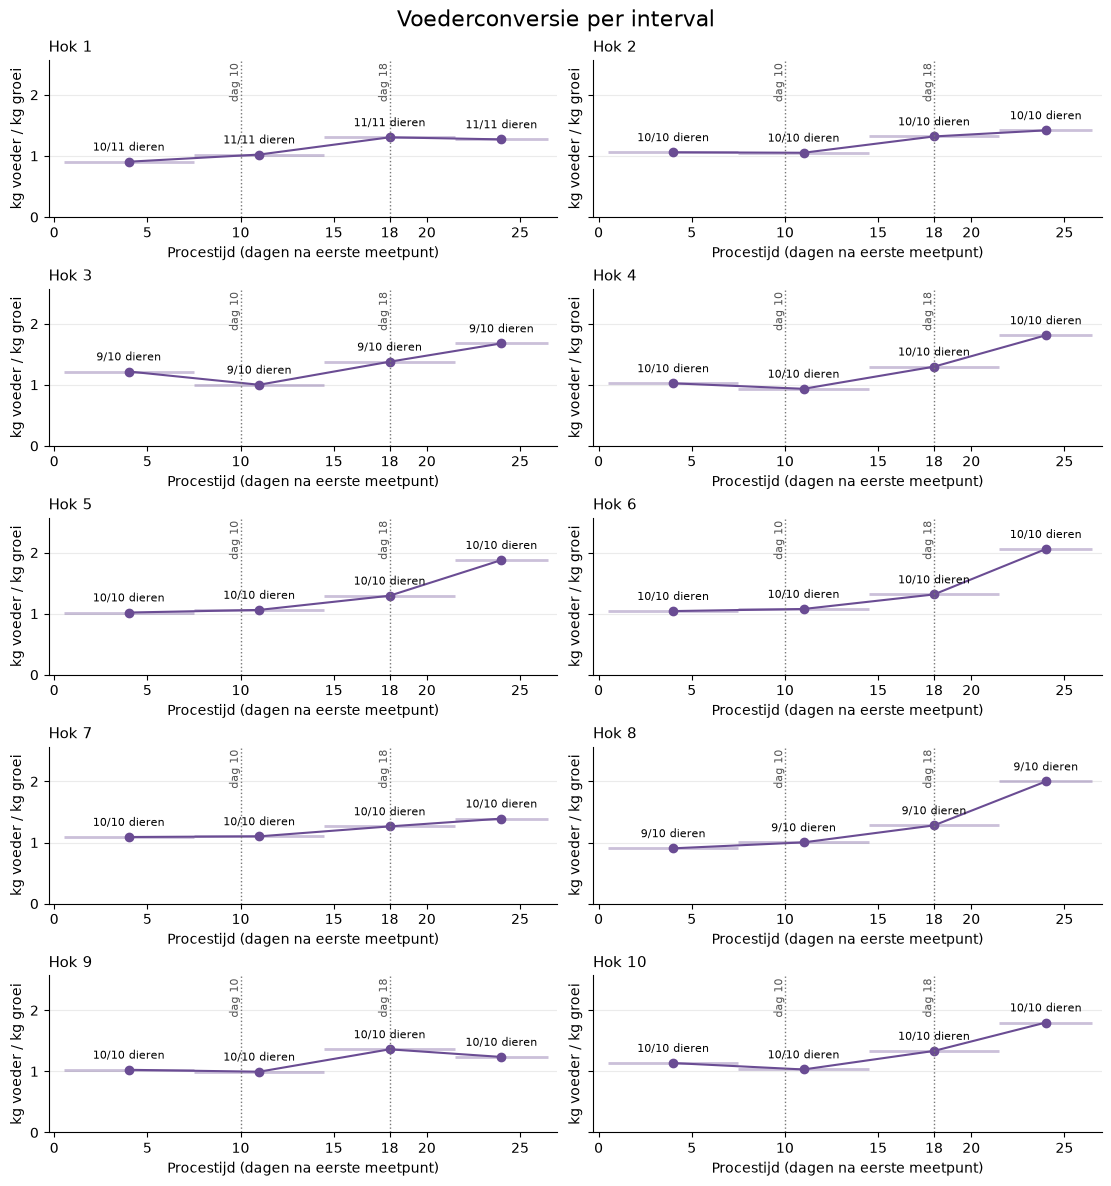

In [18]:
fig_conversie = intervalfiguur(hokresultaten, "conversie", start=processtart)
plt.show()

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

*Figuur 4. Voederconversie op basis van de totale opname en totale groei van alle bruikbare dieren in een hok. Het label `n` toont het aantal bruikbare dieren tegenover het totale aantal gekoppelde dieren in dat hok.*

</div>

<div style="background-color:#e3f2fd;color:#0d47a1;border-left:5px solid #1976d2;padding:14px;margin:12px 0;border-radius:4px;text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;white-space:normal;"><strong>Facultatieve verkenning 2</strong><br>Teken voor één interval een spreidingsgrafiek met gemiddelde groei op de horizontale as en voederconversie op de verticale as, en zet bij elk punt het hoknummer. Welk hok combineert snelle groei met een lage conversie? Probeer daarna een ander interval om te zien of hetzelfde hok bovenaan blijft.</div>

In [19]:
# FACULTATIEF:
# Selecteer één interval uit hokresultaten in verkenning_selectie.
# Gebruik ax.scatter(groei_g_dier_dag, voederconversie).
# Voeg hoknummers toe met ax.annotate en benoem de eenheden.

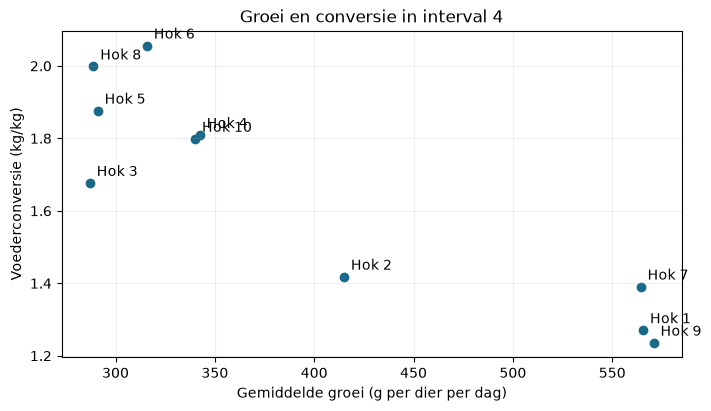

In [20]:
verkenning_interval = 4
verkenning_selectie = hokresultaten[hokresultaten["interval"] == verkenning_interval]
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.scatter(verkenning_selectie["groei_g_dier_dag"], verkenning_selectie["voederconversie"], color="#176a89")
for rij in verkenning_selectie.itertuples():
    ax.annotate(f"Hok {rij.hok}", (rij.groei_g_dier_dag, rij.voederconversie), xytext=(5, 5), textcoords="offset points")
ax.set(xlabel="Gemiddelde groei (g per dier per dag)", ylabel="Voederconversie (kg/kg)",
       title=f"Groei en conversie in interval {verkenning_interval}")
ax.grid(alpha=.2)
plt.show()

## 9. Verschillen interpreteren en een vervolgvraag formuleren

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

In deze proef zijn vier verschillende voederstrategieën gebruikt: de biggen kregen eerst voer met een hoger of een lager eiwitgehalte, en schakelden na tien of na achttien dagen over naar hetzelfde vervolgvoeder. De tabel vat de vier strategieën samen. Met de patronen in je grafieken ga je na welke verklaringen daarbij passen.

</div>

| Strategie | Eiwitgehalte eerste voeder | Overschakeling | Eiwitgehalte vervolgvoeder |
|---|---|---|---|
| Hoger eiwit, kort | 188 g ruw eiwit/kg | Na 10 dagen | 179 g/kg |
| Hoger eiwit, lang | 188 g ruw eiwit/kg | Na 18 dagen | 179 g/kg |
| Lager eiwit, kort | 162 g ruw eiwit/kg | Na 10 dagen | 179 g/kg |
| Lager eiwit, lang | 162 g ruw eiwit/kg | Na 18 dagen | 179 g/kg |

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

Snellere groei alleen bewijst nog niet welke strategie een hok kreeg, want ook het startgewicht, de opname, uitval, meetkwaliteit en natuurlijke verschillen tussen dieren spelen mee. De grafieken leveren dus goede aanknopingspunten voor een hypothese, maar nog geen sluitend bewijs.

Voor een echte bedrijfskeuze kijk je ook verder dan alleen de laagste voederconversie: groeisnelheid, diergezondheid en voerkosten tellen net zo goed mee (al berekenen we die laatste twee hier niet). In notebook 08 toets je jouw voorlopige indruk opnieuw zodra ook de latere meetdagen zijn toegevoegd.

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Vraag 4.** Vergelijk hok 1 en hok 9 in het eerste en laatste interval. Blijft de rangorde voor voederconversie gelijk?

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Jouw antwoord (Vraag 4):**

*Voeg hier je antwoord in. Tip: noteer vier waarden en controleer de aantallen dieren.*

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Antwoord 4**

In het eerste interval heeft hok 1 een voederconversie van 0.905 en hok 9 van 1.026. In het laatste interval draait dat om naar 1.271 voor hok 1 tegenover 1.236 voor hok 9. Eerst tellen in beide hokken 10 dieren mee, later 11 in hok 1 en 10 in hok 9. Om dat verschil goed te beoordelen bekijk ik ook de tijdafstanden van de gebruikte gewichten en het aantal dagen met voederregistraties.

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Vraag 5.** Welk hok wil je nader onderzoeken, en welke extra informatie heb je nodig voordat je een voederstrategie aanbeveelt?

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Jouw antwoord (Vraag 5):**

*Voeg hier je antwoord in. Tip: gebruik minstens één getal uit een figuur of tabel en benoem een beperking.*

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Antwoord 5**

Hok 9 haalt in het laatste interval een gemiddelde groei van 570.8 g per dier per dag met een voederconversie van 1.236. In notebook 08 onderzoek ik of dat gunstige patroon doorzet zodra de latere dagen erbij komen. Voor een echt bedrijfsadvies heb ik bovendien informatie nodig over welke strategie elk hok kreeg, de voerprijzen, de diergezondheid en de dekking (aantal dieren, tijdafstand en voederregistratie).

</div>

## 10. De beginsituatie voor notebook 08 bewaren

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Uitvoeren:** in Codespaces (Notebook 07)

Je bewaart nu de berekende tabellen samen met de gebruikte populatie, tijdsgrenzen en kwaliteitsregels. Daardoor kun je in notebook 08 de nieuwe cijfers precies naast deze beginsituatie leggen. De cel schrijft de eerste keer de map `beginsituatie_07` en laat een bestaande map met dezelfde inhoud ongemoeid, zonder ooit afwijkende resultaten zomaar te overschrijven.

De figuren en het controlebestand worden vanzelf opgebouwd uit je notebook. Je hoeft dus geen los verslag te schrijven, maar vult wel je antwoorden bij de vragen in.

</div>

In [21]:
inlevermap = hoofdmap / "gegevens/inlevering"
basisbeschrijving = bewaar_basis(inlevermap / "beginsituatie_07", populatie, dag,
                                dierintervallen, hokresultaten, bronmanifest, regels)
for naam, figuur in [("07_gewichtsverloop.png", fig_gewicht),
                    ("07_groei_en_voederopname.png", fig_groei_voeder),
                    ("07_voederconversie.png", fig_conversie)]:
    figuur.savefig(inlevermap / naam, dpi=140, bbox_inches="tight")
controle = {
    "deelnemerscode": deelnemer, "branch": branch, "rol": rol,
    "getest_op_utc": datetime.now(timezone.utc).isoformat(), "methode": METHODE,
    "populatie": len(populatie), "hokken": hokvolgorde(populatie["hok"]),
    "bruikbare_dieren_per_interval": {str(k): int(v) for k, v in dierintervallen.groupby("interval")["bruikbaar"].sum().items()},
    "gekozen_hok": gekozen_hok, "gekozen_interval": gekozen_interval,
    "eigen_voederconversie": float(eigen_conversie), "basis": basisbeschrijving,
}
(inlevermap / "07_analysecontrole.json").write_text(json.dumps(controle, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print("Beginsituatie, drie figuren en 07_analysecontrole.json bewaard.")
print("Herhaling bewaren:", bewaar_basis(inlevermap / "beginsituatie_07", populatie, dag,
                                       dierintervallen, hokresultaten, bronmanifest, regels) == basisbeschrijving)

Beginsituatie, drie figuren en 07_analysecontrole.json bewaard.
Herhaling bewaren: True


<div style="background-color:#e8f5e9;color:#1b5e20;border-left:5px solid #2e7d32;padding:14px;margin:12px 0;border-radius:4px;text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;white-space:normal;"><strong>Controle</strong><br>De map <code>beginsituatie_07</code> bewaart de populatie, daggewichten, dierintervallen, hokresultaten en een overzicht met controlesommen. Wil je later toch iets met een andere methode uitproberen, bewaar dat dan apart en wis de oorspronkelijke beginsituatie niet om een verschilmelding te verbergen.</div>

<div style="background-color:#fff8e1;color:#6d4c00;border-left:5px solid #f9a825;padding:14px;margin:12px 0;border-radius:4px;text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;white-space:normal;"><strong>Stop je Codespace na het practicum</strong><br>Bewaar je werk, commit en push voordat je de Codespace stopt. Je Droplet heeft afzonderlijke kosten en blijft beschikbaar volgens de afspraak met de docent.</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Uitvoeren:** in Codespaces (Source Control) en op de GitHub-website

1. Vul al je antwoorden aan en kies **File → Save All**.
2. Selecteer in **Source Control** dit notebook, `07_analysecontrole.json`, de drie `07_...png`-figuren en alle bestanden in `gegevens/inlevering/beginsituatie_07/`.
3. Commit met bijvoorbeeld **Groei en voederconversie per hok onderzocht**, kies **Push** en controleer op GitHub of alles op je branch staat.
4. `analyse_06.db` blijft onder `gegevens/werk/` staan en gaat niet mee naar GitHub. Hervat later dezelfde Codespace, of bouw het bestand via notebook 06 opnieuw op als je ooit een nieuwe Codespace start.
5. Stop je Codespace via [github.com/codespaces](https://github.com/codespaces).

In notebook 08 voeg je de latere meetdagen toe en leg je zowel de vaste beginperiode als de nieuwe periode naast elkaar.

</div>

## Hulp bij veelvoorkomende problemen

| Probleem | Controle en herstel |
|---|---|
| `analyse_06.db` of controlebestand ontbreekt | Open notebook 06 in dezelfde Codespace en voer de inlevercel opnieuw uit. |
| Inhoud wijkt af van 06 | Controleer of je het juiste analysebestand gebruikt en of de API-import later opnieuw gedraaid is. |
| Dubbele identificatie of verkeerde eenheid | Herstel eerst de import uit 06, en verwijder geen records met de hand om door te kunnen gaan. |
| Ontbrekend grensgewicht | Controleer of een dier minstens vijf gewichtsmetingen heeft en hoe ver die van de periodegrens liggen. |
| Voederdagen ontbreken | Geen geregistreerde voederdag is niet hetzelfde als nul opname. Controleer de periode en ontvangst. |
| Geen positieve groei | Bij groei kleiner dan of gelijk aan nul wordt geen voederconversie berekend. Bekijk eerst het dier en de meetkwaliteit. |
| Onverwacht lage of hoge conversie | Kijk naar de opname, het begin- en eindgewicht, het interval en de dekking voordat je conclusies trekt. |
| Beginsituatie verschilt | Bewaar de oorspronkelijke map, controleer wat er gewijzigd is en maak voor een proef eventueel een aparte kopie. |
| NameError na hervatten | Voer de codecellen opnieuw in volgorde uit. Bestanden blijven bewaard, maar Python-variabelen in het geheugen verdwijnen na het stoppen. |

## Technische bronnen en methode

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

- [Gegevenswoordenboek](../../gegevens/gegevenswoordenboek.md)
- [Rekenmethode en referentiecontrole](../../documentatie/rekenmethode_07.md)
- [Ontario: voederopname, groei en voederconversie bij varkens](https://www.ontario.ca/page/providing-feed-and-water-pigs)
- [pandas: groeperen en aggregeren](https://pandas.pydata.org/docs/user_guide/groupby.html)
- [Matplotlib: figuren met meerdere panelen](https://matplotlib.org/stable/gallery/subplots_axes_and_figures/subplots_demo.html)

De brongegevens komen uit een voederproef met 101 biggen. De berekening in dit notebook is een overzichtelijke methode om de hokgegevens te verkennen. Omdat de oorspronkelijke datasets al kwaliteitsvlaggen uit de verwerking bevatten, gaat het om een analyse achteraf en geen blinde voorspelling.

</div>